<a href="https://colab.research.google.com/github/iralsd/-------------/blob/main/lerning_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
print(train.shape, test.shape)

(8693, 14) (4277, 13)


In [ ]:
train.isna().sum()
print((train.isna().mean() * 100).round(2).sort_values(ascending=False))

CryoSleep       2.50
ShoppingMall    2.39
VIP             2.34
HomePlanet      2.31
Name            2.30
Cabin           2.29
VRDeck          2.16
Spa             2.11
FoodCourt       2.11
Destination     2.09
RoomService     2.08
Age             2.06
PassengerId     0.00
Transported     0.00
dtype: float64


много столбцов с пропущенными данными, в каждом примено 2% данных потеряно, если. удалять столбцы или строки будет плохо, поэтому заполняем вот

In [ ]:
def prepare(df):
    df = df.copy()
    spend = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

    # если чел в креосне как он может тратить
    m = df["CryoSleep"] == True
    df.loc[m, spend] = df.loc[m, spend].fillna(0)

    df["TotalSpend"] = df[spend].sum(axis=1)

    # ну если человек лавешку тратил занчит он не креосне
    df.loc[df["CryoSleep"].isna() & (df["TotalSpend"] > 0), "CryoSleep"] = False

    # непонятные данные которые чета дают мало нам раздеяем,
    # ну выделяем номер группы и сколько челов в ней, сам чел один или с компашкой был
    df["Group"] = df["PassengerId"].str.split("_").str[0]
    df["GroupSize"] = df.groupby("Group")["PassengerId"].transform("count")
    # ну выделяем палубу и и сторону номер каюты не нужон
    df["Deck"] = df["Cabin"].str.split("/").str[0]
    df["Side"] = df["Cabin"].str.split("/").str[2]

    for c in ["CryoSleep", "VIP"]:# хочу строчку
        df[c] = df[c].map({True: "yes", False: "no"})

    return df.drop(columns=["PassengerId", "Name", "Cabin", "Group"])

y = train["Transported"].astype(int)#хочуу число
X = prepare(train.drop(columns=["Transported"]))
X_test = prepare(test)
X.head()

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,TotalSpend,GroupSize,Deck,Side
0,Europa,no,TRAPPIST-1e,39.0,no,0.0,0.0,0.0,0.0,0.0,0.0,1,B,P
1,Earth,no,TRAPPIST-1e,24.0,no,109.0,9.0,25.0,549.0,44.0,736.0,1,F,S
2,Europa,no,TRAPPIST-1e,58.0,yes,43.0,3576.0,0.0,6715.0,49.0,10383.0,2,A,S
3,Europa,no,TRAPPIST-1e,33.0,no,0.0,1283.0,371.0,3329.0,193.0,5176.0,2,A,S
4,Earth,no,TRAPPIST-1e,16.0,no,303.0,70.0,151.0,565.0,2.0,1091.0,1,F,S


In [ ]:
num_cols = ["Age", "RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck", "TotalSpend", "GroupSize"]
cat_cols = ["HomePlanet", "CryoSleep", "Destination", "VIP", "Deck", "Side"]

In [ ]:
from sklearn.impute import SimpleImputer

num_imp = SimpleImputer(strategy="median")
cat_imp = SimpleImputer(strategy="most_frequent")

X[num_cols] = num_imp.fit_transform(X[num_cols])
X[cat_cols] = cat_imp.fit_transform(X[cat_cols])
X_test[num_cols] = num_imp.transform(X_test[num_cols])
X_test[cat_cols] = cat_imp.transform(X_test[cat_cols])

print(X.isna().sum().sum(), X_test.isna().sum().sum())

0 0


In [30]:
vis = X.copy()
vis["Transported"] = y
vis["HasSpend"] = (vis["TotalSpend"] > 0).map({True: "да", False: "нет"})

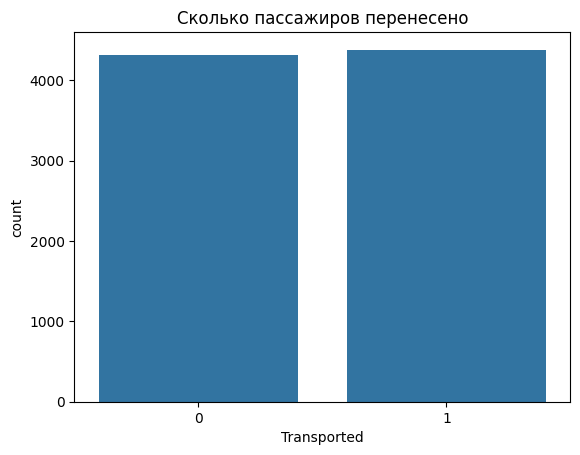

In [ ]:
sns.countplot(x="Transported", data=vis)
plt.title("Сколько пассажиров перенесено")
plt.show()


ну что, 50 на 50 людей которые перенесены и нет, Accuracy хорошо зайдет

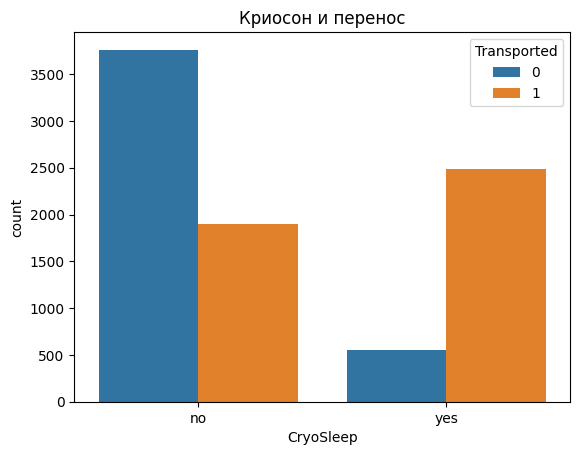

In [ ]:
sns.countplot(x="CryoSleep", hue="Transported", data=vis)
plt.title("Криосон и перенос")
plt.show()

ну людей которые спали намного больше перенесено, чем тех что не спали, вывод спать хорошо. 80 процентов спавших перенесено, а среди не спавших где-то 30.

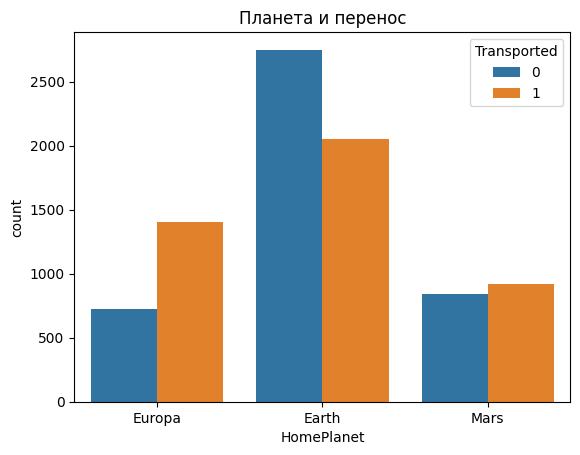

In [ ]:
sns.countplot(x="HomePlanet", hue="Transported", data=vis)
plt.title("Планета и перенос")
plt.show()

ну с земл больше всего людей, но по сравнению с другими планетами с земли больше половины не перенесены, в остальных перевес в другую сторону. с eurpa перенесено больше всего людей по соотношению

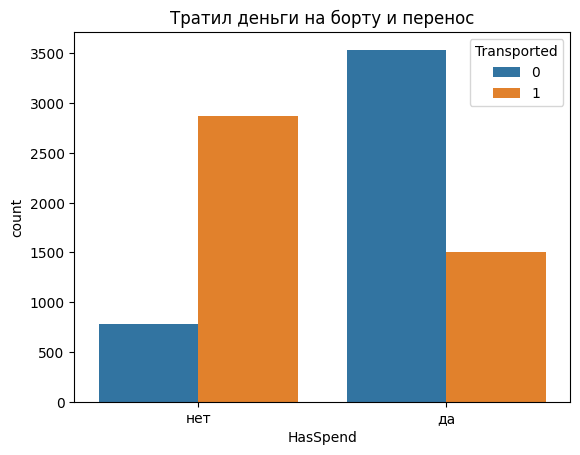

In [31]:
sns.countplot(x="HasSpend", hue="Transported", data=vis)
plt.title("Тратил деньги на борту и перенос")
plt.show()

In [ ]:
экномия спасает жизнь походу. значительная часть людей которая тратила деньги не спасена, а кто не тратил чаще были прененсены

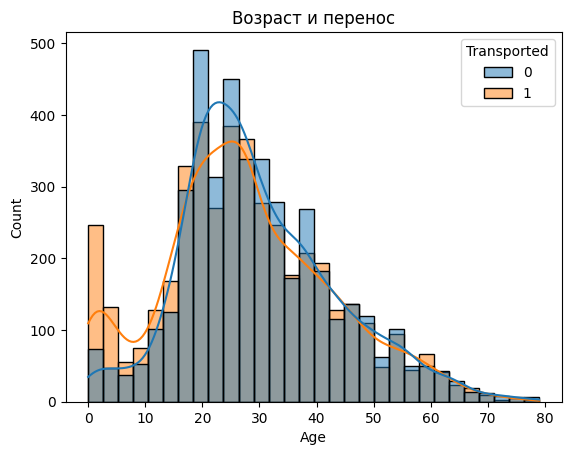

In [32]:
sns.histplot(data=vis, x="Age", hue="Transported", bins=30, kde=True)
plt.title("Возраст и перенос")
plt.show()

ну детей до 10 лет чаще переносили, а вот 20ти летних чета нет

In [ ]:
all_df = pd.concat([X, X_test], axis=0)
all_df = pd.get_dummies(all_df, columns=cat_cols, drop_first=True, dtype=int)

X_d = all_df.iloc[:len(X)].reset_index(drop=True)
X_test_d = all_df.iloc[len(X):].reset_index(drop=True)
print(X_d.shape, X_test_d.shape)

(8693, 22) (4277, 22)


In [ ]:
тут мы склеили данные заменили текстовые поля на цифирки, и разрезали

In [34]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer

scale = make_column_transformer((StandardScaler(), num_cols), remainder="passthrough")

models = {
    "LogReg": make_pipeline(scale, LogisticRegression(max_iter=2000)),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=3),
    "GradBoost": GradientBoostingClassifier(random_state=3),
}

for name, m in models.items():
    s = cross_val_score(m, X_d, y, cv=5, scoring="accuracy")
    print(name, round(s.mean(), 4), "±", round(s.std(), 4))

LogReg 0.7881 ± 0.0082
RandomForest 0.7839 ± 0.0089
GradBoost 0.799 ± 0.0104


тута мы промаштабировали, чтобы моделки лучше данные взяли. режем данные на пять частей на 4 обучаем на 5 проверяем. выводим среднее и разброс

In [35]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    {"n_estimators": [100,200, 300], "max_depth": [2, 3, 4], "learning_rate": [0.05, 0.1]},
    cv=5, scoring="accuracy")
grid.fit(X_d, y)
print(grid.best_params_, round(grid.best_score_, 4))

{'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 300} 0.8059


In [ ]:
заставляем компуктер искат лучшие параметры

In [36]:
best = GradientBoostingClassifier(**grid.best_params_, random_state=42)
best.fit(X_d, y)

sub = pd.DataFrame({"PassengerId": test["PassengerId"],
                    "Transported": best.predict(X_test_d).astype(bool)})
sub.to_csv("submission.csv", index=False)
sub.head()

,PassengerId,Transported
0,0013_01,True
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True


In [24]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

def compute_metrics(model, X_val, y_val, model_name="Model", threshold=0.5):
    y_prob = model.predict_proba(X_val)[:, 1]
    y_pred = (y_prob > threshold).astype(int)

    acc = accuracy_score(y_val, y_pred)
    prec = precision_score(y_val, y_pred)
    rec = recall_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)
    auc = roc_auc_score(y_val, y_prob)

    print(f"{model_name} (порог {threshold}):\n"
          f"Accuracy: {acc*100:.2f}%, Precision: {prec:.4f}, Recall: {rec:.4f}, "
          f"F1: {f1:.4f}, ROC-AUC: {auc:.4f}\n")

In [23]:
from sklearn.model_selection import train_test_split

X_tr, X_val, y_tr, y_val = train_test_split(
    X_d, y, test_size=0.2, random_state=42, stratify=y)

In [25]:
lr = make_pipeline(scale, LogisticRegression(max_iter=2000))
rf = RandomForestClassifier(n_estimators=300, random_state=42)
gb = GradientBoostingClassifier(**grid.best_params_, random_state=42)

lr.fit(X_tr, y_tr)
rf.fit(X_tr, y_tr)
gb.fit(X_tr, y_tr)

compute_metrics(lr, X_val, y_val, "LogisticRegression")
compute_metrics(rf, X_val, y_val, "RandomForest")
compute_metrics(gb, X_val, y_val, "GradientBoosting (GridSearch)")

LogisticRegression (порог 0.5):
Accuracy: 79.13%, Precision: 0.7879, Recall: 0.8014, F1: 0.7946, ROC-AUC: 0.8814

RandomForest (порог 0.5):
Accuracy: 79.93%, Precision: 0.8186, Recall: 0.7728, F1: 0.7951, ROC-AUC: 0.8752

GradientBoosting (GridSearch) (порог 0.5):
Accuracy: 81.08%, Precision: 0.8015, Recall: 0.8299, F1: 0.8155, ROC-AUC: 0.8976



In [26]:
import pandas as pd

proba = gb.predict_proba(X_val)[:, 1]
rows = []
for t in [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7]:
    pred = (proba > t).astype(int)
    rows.append({"порог": t,
                 "Accuracy": round(accuracy_score(y_val, pred), 4),
                 "Precision": round(precision_score(y_val, pred), 4),
                 "Recall": round(recall_score(y_val, pred), 4),
                 "F1": round(f1_score(y_val, pred), 4)})

pd.DataFrame(rows)

,порог,Accuracy,Precision,Recall,F1
0,0.30,0.7982,0.7433,0.9155,0.8205
1,0.35,0.8028,0.7575,0.8950,0.8205
2,0.40,0.8091,0.7715,0.8824,0.8232
3,0.45,0.8171,0.7918,0.8642,0.8264
4,0.50,0.8108,0.8015,0.8299,0.8155
5,0.55,0.8056,0.8321,0.7694,0.7995
6,0.60,0.7947,0.8512,0.7180,0.7789
7,0.65,0.7872,0.8787,0.6701,0.7604
8,0.70,0.7700,0.9020,0.6096,0.7275
